# DSN Bootcamp Qualification Hackathon 2026 — ML Track
### Predicting `total_sales`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)

pd.set_option("display.max_columns", 200)
sns.set_style('whitegrid')

In [2]:
train_df = pd.read_csv("train.csv") # Load the training data
test_df = pd.read_csv("test.csv") # Load the test data

In [3]:
print(f"Train shape: {train_df.shape}")
print(f"Test shape:  {test_df.shape}")

Train shape: (6818, 13)
Test shape:  (1705, 12)


In [4]:
train_df.head()

,id,product_code,product_weight_kg,fat_content,shelf_visibility,product_category,product_price,store_code,store_age_years,store_size,store_location_tier,store_format,total_sales
0,row_00000,PRD-PRFP9S,14.252,Low Fat,0.0271,Frozen Foods,81.37,STORE-AGY,45,Large,Tier_3,Standard Supermarket,1764.98
1,row_00001,PRD-PXXK71,7.698,Low Fat,0.0720,HEALTH AND HYGIENE,42.05,STORE-YLW,35,Small,Tier_1,Standard Supermarket,342.13
2,row_00002,PRD-V5MOIJ,14.264,Regular,0.0421,Canned,41.35,STORE-89Z,33,Medium,Tier_1,Standard Supermarket,378.85
3,row_00003,PRD-UN5Z3J,NaN,Regular,0.0449,soft drinks,174.35,STORE-7WS,47,Medium,Tier_3,Flagship Hypermarket,5595.72
4,row_00004,PRD-6RDQYB,10.338,Regular,0.0120,meat,203.06,STORE-9RG,28,Small,Tier_2,Standard Supermarket,2375.36


In [5]:
train_df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 6818 entries, 0 to 6817
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   6818 non-null   str    
 1   product_code         6818 non-null   str    
 2   product_weight_kg    5593 non-null   float64
 3   fat_content          6818 non-null   str    
 4   shelf_visibility     6818 non-null   float64
 5   product_category     6818 non-null   str    
 6   product_price        6818 non-null   float64
 7   store_code           6818 non-null   str    
 8   store_age_years      6818 non-null   int64  
 9   store_size           4899 non-null   str    
 10  store_location_tier  6818 non-null   str    
 11  store_format         6818 non-null   str    
 12  total_sales          6818 non-null   float64
dtypes: float64(4), int64(1), str(8)
memory usage: 692.6 KB


From the info, we see that `product_weight_kg` and `store_size` have missing values. These have to be handled before modeling.

In [6]:
train_df.describe()

,product_weight_kg,shelf_visibility,product_price,store_age_years,total_sales
count,5593.000000,6818.000000,6818.000000,6818.000000,6818.000000
mean,12.850876,0.065527,140.473623,34.178205,2174.756574
std,4.646542,0.051566,62.413513,8.384574,1697.894956
min,4.482000,0.000000,31.110000,23.000000,32.700000
25%,8.750000,0.026600,93.280000,28.000000,834.792500
50%,12.647000,0.053200,142.065000,33.000000,1790.890000
75%,16.894000,0.093400,185.987500,45.000000,3092.587500
max,21.883000,0.320100,273.040000,47.000000,12996.820000


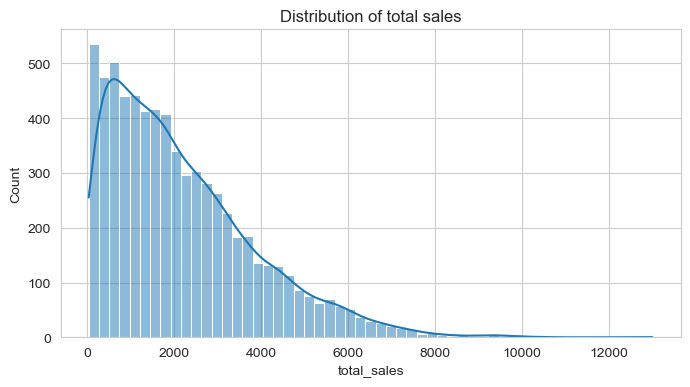

In [7]:
# Let's see what the target looks like

TARGET = "total_sales"


plt.figure(figsize=(8, 4))
sns.histplot(data=train_df, x=TARGET, kde=True)

plt.title("Distribution of total sales")
plt.show()

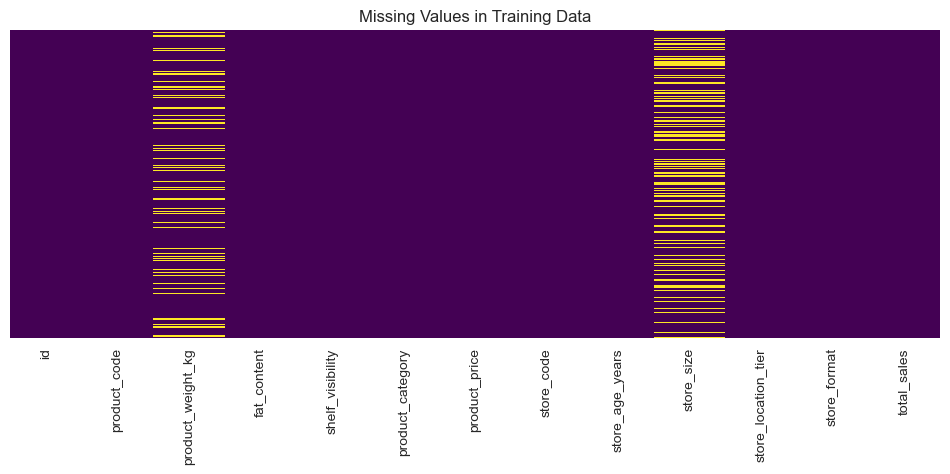

In [9]:
plt.figure(figsize=(12, 4))
sns.heatmap(train_df.isnull(), yticklabels=False, cbar=False, cmap="viridis")

plt.title("Missing Values in Training Data")
plt.show()

In [84]:
train_df["store_code"].value_counts()

store_code
STORE-YLW    754
STORE-9RG    752
STORE-AGY    748
STORE-7WS    748
STORE-OYG    744
STORE-HL7    742
STORE-DKU    736
STORE-89Z    728
STORE-JOR    439
STORE-T5G    427
Name: count, dtype: int64

In [11]:
train_df.groupby("store_code")["store_size"].unique()
# The result shows that each store code has a unique store size.

store_code
STORE-7WS    [Medium]
STORE-89Z    [Medium]
STORE-9RG     [Small]
STORE-AGY     [Large]
STORE-DKU       [nan]
STORE-HL7    [Medium]
STORE-JOR       [nan]
STORE-OYG       [nan]
STORE-T5G     [Small]
STORE-YLW     [Small]
Name: store_size, dtype: object

So there are just 10 stores in total. 7 of them have known sizes while 3 do not. 

In [13]:
train_df.groupby("store_code")["store_location_tier"].unique()
# The result shows that each store code has a unique store_location_tier. 

store_code
STORE-7WS    [Tier_3]
STORE-89Z    [Tier_1]
STORE-9RG    [Tier_2]
STORE-AGY    [Tier_3]
STORE-DKU    [Tier_2]
STORE-HL7    [Tier_3]
STORE-JOR    [Tier_3]
STORE-OYG    [Tier_2]
STORE-T5G    [Tier_1]
STORE-YLW    [Tier_1]
Name: store_location_tier, dtype: object

In [87]:
train_df.groupby("store_code")["store_format"].unique()
# Each store code also has a unique store_format.

store_code
STORE-7WS    [Flagship Hypermarket]
STORE-89Z    [Standard Supermarket]
STORE-9RG    [Standard Supermarket]
STORE-AGY    [Standard Supermarket]
STORE-DKU    [Standard Supermarket]
STORE-HL7              [Superstore]
STORE-JOR             [Corner Shop]
STORE-OYG    [Standard Supermarket]
STORE-T5G             [Corner Shop]
STORE-YLW    [Standard Supermarket]
Name: store_format, dtype: object

Each `store_code` has one `store_size`, one `store_format`, and one `store_location_tier`. Therefore, we can use those relationships to impute the missing `store_size` values.

In [89]:
summary = (train_df.groupby("store_code").agg({
                "store_size": lambda x: x.unique().tolist(),
                "store_location_tier": lambda x: x.unique().tolist(),
                "store_format": lambda x: x.unique().tolist(),
                # The numeric column 
                TARGET: ["mean", "median"],
        }
    )
    .reset_index()
)

# View the result
print(summary)


  store_code store_size store_location_tier            store_format  \
               <lambda>            <lambda>                <lambda>   
0  STORE-7WS   [Medium]            [Tier_3]  [Flagship Hypermarket]   
1  STORE-89Z   [Medium]            [Tier_1]  [Standard Supermarket]   
2  STORE-9RG    [Small]            [Tier_2]  [Standard Supermarket]   
3  STORE-AGY    [Large]            [Tier_3]  [Standard Supermarket]   
4  STORE-DKU      [nan]            [Tier_2]  [Standard Supermarket]   
5  STORE-HL7   [Medium]            [Tier_3]            [Superstore]   
6  STORE-JOR      [nan]            [Tier_3]           [Corner Shop]   
7  STORE-OYG      [nan]            [Tier_2]  [Standard Supermarket]   
8  STORE-T5G    [Small]            [Tier_1]           [Corner Shop]   
9  STORE-YLW    [Small]            [Tier_1]  [Standard Supermarket]   

   total_sales            
          mean    median  
0  3660.182219  3348.085  
1  2365.926745  2003.490  
2  2479.168098  2139.320  
3  2254.8901

From the table: `STORE-DKU` and `STORE-OYG` are Standard Supermarkets in Tier_2, so we impute them as **Small**. becasue the other Tier_2 Standard Supermarket (STORE-9RG) is "Small".  

`STORE-JOR` is a Corner Shop in Tier_3 and its average sales are close to that of `STORE-T5G` (a Corner Shop in Tier_1), which is "Small". However, since there is no other corner shop in Tier_3 to compare with, we impute it using the mode `store_size` in Tier_3, which is **Medium**.

In [39]:
# Now let's see what product_weight_kg looks like
train_df["product_weight_kg"].value_counts()

# The result shows that there are a lot of items and most of them appear very few times.

product_weight_kg
7.692     5
8.097     5
8.764     4
17.006    4
17.659    4
         ..
13.722    1
18.365    1
15.770    1
17.665    1
16.703    1
Name: count, Length: 4675, dtype: int64

<Figure size 1000x400 with 0 Axes>

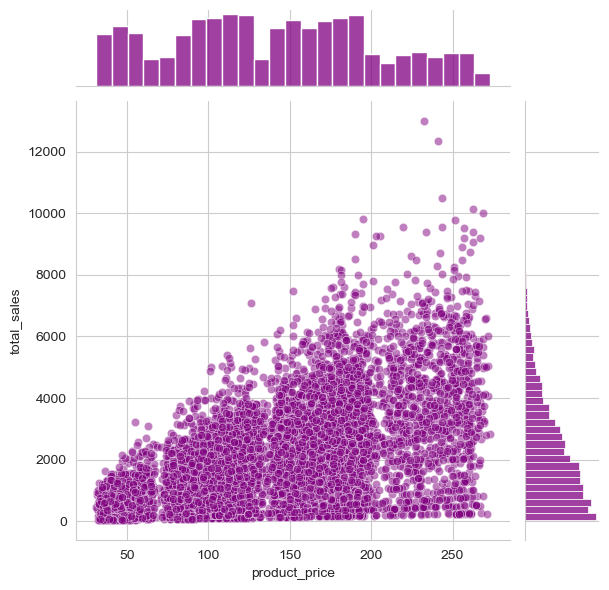

In [21]:
# Compare product price with total sales
plt.figure(figsize=(10, 4))
sns.jointplot(x= "product_price", y= TARGET, data= train_df, color= "purple", alpha= 0.5)

plt.show()


<Figure size 1000x400 with 0 Axes>

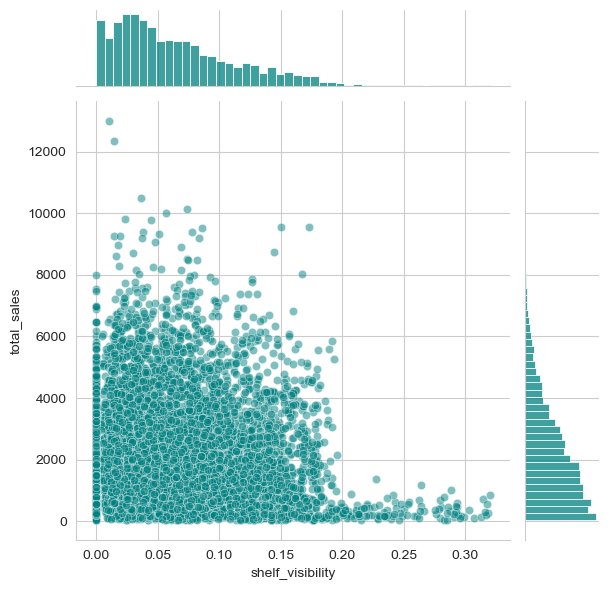

In [20]:
# Compare shelf visibility with total sales
plt.figure(figsize=(10, 4))
sns.jointplot(x="shelf_visibility", y=TARGET, data=train_df, color='teal', alpha=0.5)

plt.show()

`product_price` has a positive relationship with `total_sales`.
While `shelf_visibility` shows an inverse relationship. Items with high visibility values (the ones nearer to 0) are likely those that are prominent on shelves, and in turn, they tend to sell more.

In [22]:
# Let's see product_category

print(train_df["product_category"].value_counts(), "\n")

product_category
Fruits and Vegetables    480
Snack Foods              468
Household                387
Frozen Foods             326
Canned                   271
Dairy                    269
fruits and vegetables    265
FRUITS AND VEGETABLES    261
Baking Goods             254
snack foods              236
SNACK FOODS              229
Health and Hygiene       197
HOUSEHOLD                185
Soft Drinks              178
frozen foods             177
FROZEN FOODS             172
household                168
Meat                     157
DAIRY                    143
dairy                    142
BAKING GOODS             137
canned                   129
baking goods             125
CANNED                   117
health and hygiene       116
Breads                   110
SOFT DRINKS              100
HEALTH AND HYGIENE        99
MEAT                      94
Hard Drinks               92
soft drinks               88
meat                      88
Others                    73
Starchy Foods             

In [92]:
# Some of the values are recurring, but are in different cases and spelling
# Snack Foods vs snack foods  vs SNACK FOODS  
# fruits and vegetables  vs FRUITS AND VEGETABLES  vs Fruits and Vegetables
# frozen foods vs Frozen Foods  vs   FROZEN FOODS 
# dairy vs DAIRY
# Household vs HOUSEHOLD vs household
# Baking Goods vs BAKING GOODS  vs baking goods  And then there's "Breads vs BREADS vs breads" in a separate category
# meat vs MEAT vs Meat
# hard drinks  vs HARD DRINKS   vs Hard Drinks  vs 
# canned vs CANNED 
# SEAFOOD  vs seafood 
# Soft Drinks vs    SOFT DRINKS     vs soft drinks
# canned vs CANNED
# Health and Hygiene    vs health and hygiene   vs HEALTH AND HYGIENE
# seafood vs SEAFOOD    vs Seafood    
# Starchy Foods     vs STARCHY FOODS   vs starchy foods
# others vs Others  vs OTHERS                    
# Breakfast     vs breakfast

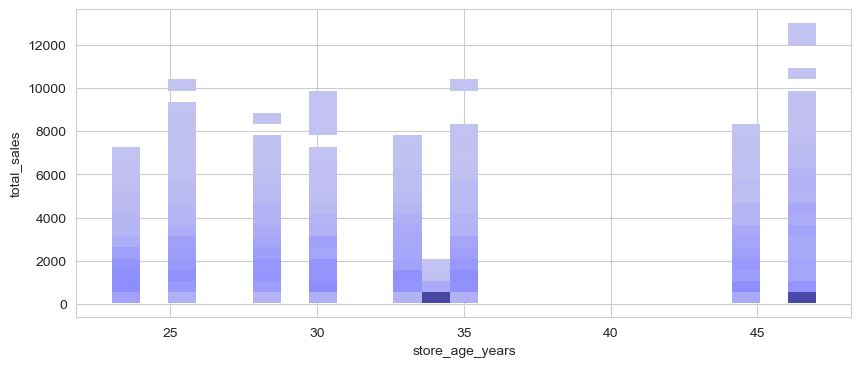

In [30]:
# Compare store age years with total sales
plt.figure(figsize=(10,4))

sns.histplot(data=train_df, x="store_age_years", y="total_sales", color="blue", bins=25)
plt.show()

There isn't a defined relationship between store age and total sales.

In [23]:
train_df[['product_weight_kg', "shelf_visibility", "product_price", "store_age_years", TARGET]].corr()

,product_weight_kg,shelf_visibility,product_price,store_age_years,total_sales
product_weight_kg,1.000000,-0.013986,0.034824,0.009020,0.015532
shelf_visibility,-0.013986,1.000000,0.003905,0.071078,-0.118124
product_price,0.034824,0.003905,1.000000,-0.012747,0.569833
store_age_years,0.009020,0.071078,-0.012747,1.000000,0.039443
total_sales,0.015532,-0.118124,0.569833,0.039443,1.000000


## Data Cleaning and Feature Engineering


In [31]:
train_df = train_df.copy() 
test_df = test_df.copy() 

### Standardize texts in `product_category`  
The texts in `product_category` are duplicated but with inconsistent casing. So convert each text row to lowercase and remove white space

In [32]:
train_df["product_category"] = train_df["product_category"].str.strip().str.lower()
test_df["product_category"] = test_df["product_category"].str.strip().str.lower()


train_df["product_category"].value_counts()

product_category
fruits and vegetables    1006
snack foods               933
household                 740
frozen foods              675
dairy                     554
canned                    517
baking goods              516
health and hygiene        412
soft drinks               366
meat                      339
breads                    209
hard drinks               169
others                    132
starchy foods             113
breakfast                  85
seafood                    52
Name: count, dtype: int64

### Impute missing values in `store_size`

Use the store-level mapping that we found during Exploratory Data Analysis.

In [33]:
store_size_fill = {
    "STORE-DKU": "Small",
    "STORE-JOR": "Medium",
    "STORE-OYG": "Small",
}

train_df["store_size"] = train_df["store_size"].fillna(
    train_df["store_code"].map(store_size_fill)
)
test_df["store_size"] = test_df["store_size"].fillna(test_df["store_code"].map(store_size_fill))

print("Remaining missing store_size — train:", train_df["store_size"].isna().sum(),
      "| test:", test_df["store_size"].isna().sum())

Remaining missing store_size — train: 0 | test: 0


### Impute missing values in `product_weight_kg`  
We use the median value of that product's category and as backup, we use the overall median.

In [ ]:
# Get the median weight for each individual product category and the overall median weight
category_weight_median = train_df.groupby("product_category")["product_weight_kg"].median()
overall_weight_median = train_df["product_weight_kg"].median()

# Fill missing weights using the product category's median
train_df["product_weight_kg"] = train_df["product_weight_kg"].fillna(
    train_df["product_category"].map(category_weight_median))

# Fill any remaining missing weights with the overall median
train_df["product_weight_kg"] = train_df["product_weight_kg"].fillna(overall_weight_median)


# For test data as well
test_df["product_weight_kg"] = test_df["product_weight_kg"].fillna(
    test_df["product_category"].map(category_weight_median))

test_df["product_weight_kg"] = test_df["product_weight_kg"].fillna(overall_weight_median)


# Now we verify by counting the remaining missing values (should be 0 for both)
print("Missing values for product_weight_kg \n train:", train_df["product_weight_kg"].isna().sum(),
      "| test:", test_df["product_weight_kg"].isna().sum())

Missing values for product_weight_kg 
 train: 0 | test: 0


## Encoding

In [41]:
# Let' see the values that need to be encoded and see which ones have hierarchy
print(train_df["store_size"].value_counts(), "\n")
print(train_df["store_location_tier"].value_counts(), "\n")
print(train_df["store_format"].value_counts(), "\n")
print(train_df["fat_content"].value_counts())

store_size
Small     3413
Medium    2657
Large      748
Name: count, dtype: int64 

store_location_tier
Tier_3    2677
Tier_2    2232
Tier_1    1909
Name: count, dtype: int64 

store_format
Standard Supermarket    4462
Corner Shop              866
Flagship Hypermarket     748
Superstore               742
Name: count, dtype: int64 

fat_content
Low Fat    4425
Regular    2393
Name: count, dtype: int64


### Ordinal encoding  
`store_size` and `store_location_tier` have hierarchy so we use consecutive integers. 

In [42]:
# For store_size
train_df["store_size_num"] = train_df["store_size"].str.lower().str.strip().map({
    "small": 0,   "medium": 1,    "large": 2  })

test_df["store_size_num"] = test_df["store_size"].str.lower().str.strip().map({
    "small": 0,   "medium": 1,    "large": 2  })


# For store_location_tier
train_df["store_location_tier_num"] = train_df["store_location_tier"].str.lower().str.strip().map({
    "tier_3": 0,   "tier_2": 1,    "tier_1": 2 })

test_df["store_location_tier_num"] = test_df["store_location_tier"].str.lower().str.strip().map({
    "tier_3": 0,   "tier_2": 1,    "tier_1": 2 })

### One-hot encoding  
`fat_content`, `store_format`, and `product_category` have no natural order, so they'll have to be one-hot encoded.

In [45]:
categorical_cols = ["fat_content", "store_format", "product_category"]

train_encoded = pd.get_dummies(train_df, columns = categorical_cols, dtype = int)
test_encoded = pd.get_dummies(test_df, columns = categorical_cols, dtype = int)

# Now, align test columns to train columns. Any category missing in test will be filled with 0
test_encoded = test_encoded.reindex(columns=train_encoded.columns, fill_value=0)

# And any category in test but not in train is dropped, since the model has never learned from it)
test_encoded = test_encoded.drop(columns=["total_sales"], errors="ignore")


print("Train encoded shape:", train_encoded.shape)
print("Test encoded shape: ", test_encoded.shape)

Train encoded shape: (6818, 34)
Test encoded shape:  (1705, 33)


## Feature and Target Split

In [47]:
drop_cols = ["id", "product_code", "store_code", "store_size", "store_location_tier", "total_sales"]
feature_cols = [col for col in train_encoded.columns if col not in drop_cols]

X = train_encoded[feature_cols]
y = train_encoded[TARGET]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size = 0.25, random_state = 42
)

print("X_train:", X_train.shape, " X_val:", X_val.shape)

X_train: (5113, 28)  X_val: (1705, 28)


In [48]:
# Just to be sure that we're on track, but this should be empty

X.isnull().sum()[X.isnull().sum() > 0]


Series([], dtype: int64)

### Modeling 


In [49]:
def model_eval(name, model, X_tr, y_tr, X_va, y_va):
    model.fit(X_tr, y_tr)
    preds = model.predict(X_va)
    mae = mean_absolute_error(y_va, preds)
    rmse = np.sqrt(mean_squared_error(y_va, preds))
    r2 = r2_score(y_va, preds)

    print(f"{name:<18} MAE={mae}       RMSE={rmse}")
    return {"model": model, "mae": mae,     "rmse": rmse, "r2": r2}


rfr = RandomForestRegressor(n_estimators=300, random_state= 42, n_jobs = -1)
xgb = XGBRegressor(n_estimators=300, learning_rate= 0.05, random_state= 42)

results = {}
results["RandomForest"] = model_eval("RandomForest", rfr, X_train, y_train, X_val, y_val)
results["XGBoost"] = model_eval("XGBoost", xgb, X_train, y_train, X_val, y_val)

RandomForest       MAE=781.0028102639295       RMSE=1112.9928102686792
XGBoost            MAE=789.9873907263969       RMSE=1121.6417921895365


## Cross-validation

In [50]:
# Run 5-fold cross-validation 
# For the random forest model
rfr = RandomForestRegressor(n_estimators=300, random_state= 42, n_jobs = -1)
rfr_cv_scores = cross_val_score(
    rfr, X, y, cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1
    )

# Now turn the negative scores back to positive error numbers
rfr_rmse_scores = -rfr_cv_scores

# Calculate the average error and the consistency (standard deviation)
rfr_mean_error = rfr_rmse_scores.mean()
rfr_consistency = rfr_rmse_scores.std()

# Print the final report for Random Forest
print(f"RandomForest    5-fold CV RMSE: {rfr_mean_error:.2f} (+/- {rfr_consistency:.2f})"
)


# 2. For the XGBoost model
xgb = XGBRegressor(n_estimators=300, learning_rate= 0.05, random_state= 42)

# Run 5-fold cross-validation
xgb_cv_scores = cross_val_score(
    xgb, X, y, cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)

# Now turn the negative scores back to positive error numbers
xgb_rmse_scores = -xgb_cv_scores

# Calculate the average error and the consistency (standard deviation)
xgb_mean_error = xgb_rmse_scores.mean()
xgb_consistency = xgb_rmse_scores.std()

# Print the final report for XGBoost
print(f"XGBoost         5-fold CV RMSE: {xgb_mean_error:.2f} (+/- {xgb_consistency:.2f})"
)


RandomForest    5-fold CV RMSE: 1120.76 (+/- 31.93)
XGBoost         5-fold CV RMSE: 1123.28 (+/- 33.89)


On average, the Random Forest's predictions are about 1120.76 units off from the actual target values, with average error of 31.93. Which are lower than XGBoost's  1123.28 with average error of 33.89. 

## Final fit
Retrain the Random forest model on the whole training data and then predict on the encoded test data. 

In [51]:
final_model = rfr

final_model.fit(X, y)

X_test_final = test_encoded[feature_cols]
test_preds = final_model.predict(X_test_final)

submission_df = pd.DataFrame(
    { "id": test_encoded["id"],
      "total_sales": test_preds}
)

submission_df.to_csv("submission.csv", index=False)


In [52]:
submission_df.head()

,id,total_sales
0,row_00009,2751.375700
1,row_00015,4779.187233
2,row_00019,3674.830367
3,row_00020,3220.834533
4,row_00023,2547.526300
